## Cell 1: Import statements

Preprocessing notebook: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Code\models\preprocessing\01_mri_preprocessing.ipynb
Notebook exists: True
Project root: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research
Dataset found: True
Image root found: True
Total MRI images: 11520

Class distribution:
label
1    10323
0     1197
Name: count, dtype: int64

MRI sequences:
sequence
T1C+    4642
T1      3799
T2      3079
Name: count, dtype: int64

Saved manifest: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Code\preprocessing\manifests\brain_mri_master_manifest.csv


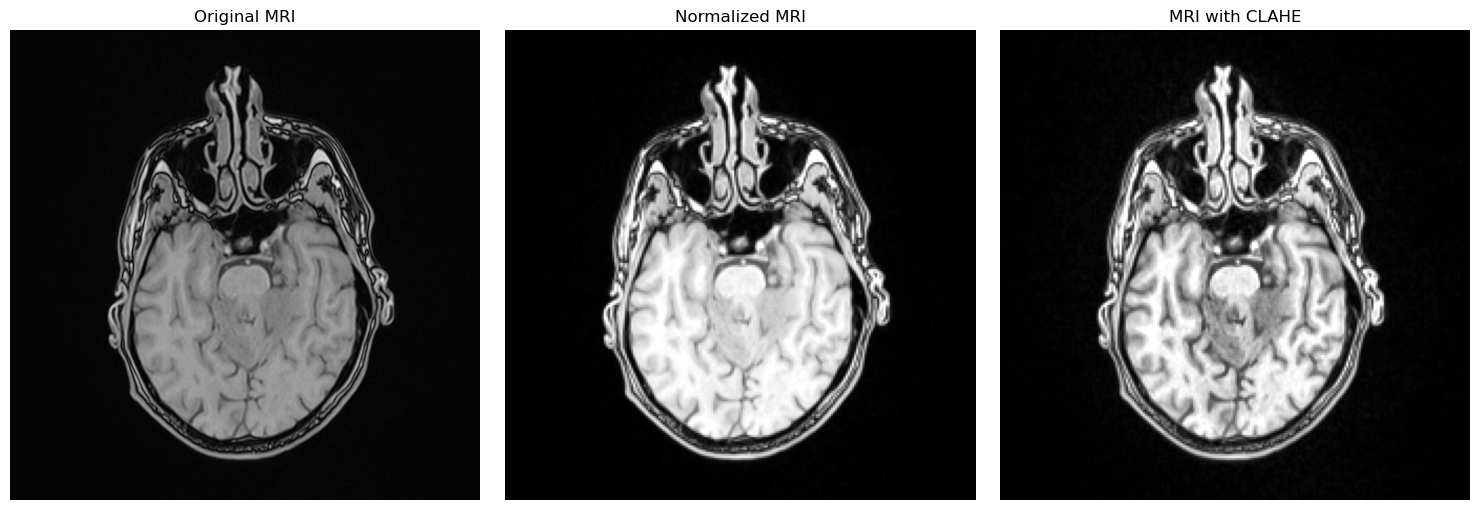

Original shape: (512, 512)
Preprocessed shape: (224, 224)
Intensity range: 0.0 1.0

Project root: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research
Preprocessing notebook: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Code\models\preprocessing\01_mri_preprocessing.ipynb
Shared preprocessing loaded successfully.


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Locate the shared preprocessing notebook
PREPROCESSING_NOTEBOOK = (
    PROJECT_ROOT /
    "Code" /
    "models" /
    "preprocessing" /
    "01_mri_preprocessing.ipynb"
)

print("Preprocessing notebook:", PREPROCESSING_NOTEBOOK)
print("Notebook exists:", PREPROCESSING_NOTEBOOK.is_file())

assert PREPROCESSING_NOTEBOOK.is_file(), (
    f"Notebook not found: {PREPROCESSING_NOTEBOOK}"
)

# Execute the shared preprocessing notebook
get_ipython().run_line_magic(
    "run",
    f'"{PREPROCESSING_NOTEBOOK}"'
)

# Establish reproducibility
SEED = 42
np.random.seed(SEED)

# Verify that the shared preprocessing function is available
assert callable(globals().get("preprocess_mri")), (
    "Shared MRI preprocessing function was not loaded."
)

print("\nProject root:", PROJECT_ROOT)
print("Preprocessing notebook:", PREPROCESSING_NOTEBOOK)
print("Shared preprocessing loaded successfully.")



## Cell 2: Load the Master MRI Manifest

### Purpose

Load the standardized MRI dataset manifest generated by the
shared preprocessing notebook.

### Description

The master manifest contains MRI image paths, binary tumor
classification labels, and associated metadata.

This cell verifies:

- Successful loading of the master manifest.
- Total number of MRI images.
- Distribution of tumor and non-tumor images.
- Availability of the required classification columns.
- Validity of image file paths.

### Why It Matters

Using a centralized dataset manifest promotes consistency,
reproducibility, and fair comparisons across all independent
baseline models and the eventual hybrid model.

In [26]:
# Locate the master MRI manifest
MANIFEST_PATH = (
    PROJECT_ROOT /
    "Code" /
    "preprocessing" /
    "manifests" /
    "brain_mri_master_manifest.csv"
)

# Verify that the manifest exists
assert MANIFEST_PATH.is_file(), (
    f"Manifest not found: {MANIFEST_PATH}"
)

# Load the master manifest
df = pd.read_csv(MANIFEST_PATH)

# Verify required columns
required_columns = {"image_path", "label"}

assert required_columns.issubset(df.columns), (
    "Required manifest columns are missing."
)

# Verify dataset integrity
assert not df.empty, "The manifest is empty."

assert df["label"].isin([0, 1]).all(), (
    "Invalid classification labels detected."
)

assert df["image_path"].is_unique, (
    "Duplicate image paths detected."
)

# Verify image paths
missing_images = df["image_path"].apply(
    lambda path: not Path(path).is_file()
).sum()

assert missing_images == 0, (
    f"{missing_images} image files are missing."
)

# Display dataset information
print("Manifest path:", MANIFEST_PATH)
print("Total MRI images:", len(df))
print("Missing images:", missing_images)

print("\nClass distribution:")
print(df["label"].value_counts().sort_index())

print("\nClass distribution (%):")
print(
    df["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(df.head())


Manifest path: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Code\preprocessing\manifests\brain_mri_master_manifest.csv
Total MRI images: 11520
Missing images: 0

Class distribution:
label
0     1197
1    10323
Name: count, dtype: int64

Class distribution (%):
label
0    10.39
1    89.61
Name: proportion, dtype: float64


,image_path,label,tumor_type,sequence,patient_id,mask_path,bbox_path,original_width,original_height
0,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,1,Medulloblastoma,T1,NaN,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,512,512
1,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,1,Medulloblastoma,T1,NaN,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,512,512
2,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,1,Medulloblastoma,T1,NaN,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,512,512
3,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,1,Medulloblastoma,T1,NaN,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,512,512
4,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,1,Medulloblastoma,T1,NaN,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,Embryonic Tumors/Embryonic Tumors T1/Medullobl...,512,512



## Cell 3: MRI Feature Extraction

### Purpose

Convert standardized MRI images into fixed-length numerical
feature vectors suitable for the Random Forest classifier.

### Description

This cell utilizes the centralized preprocess_mri() function
defined in the shared 01_mri_preprocessing.ipynb notebook.

The feature extraction process consists of:

- Shared MRI preprocessing and intensity normalization.
- Standardized image dimensions of 224 x 224 pixels.
- Dimensionality reduction to 64 x 64 pixels.
- Flattening the two-dimensional image into a one-dimensional
  feature vector containing 4,096 numerical features.

### Why It Matters

Traditional machine learning algorithms such as Random Forest
require numerical feature vectors rather than two-dimensional
image matrices.

Reusing the centralized preprocessing function eliminates
redundant preprocessing code and promotes consistency,
modularity, and reproducibility across the independent
baseline models.

This implementation establishes a raw-pixel Random Forest
classification baseline.


In [27]:

from skimage.transform import resize

# Feature extraction configuration
RF_IMAGE_SIZE = (64, 64)
USE_CLAHE = False

def extract_features(image_path):
    """
    Convert a preprocessed MRI image into a fixed-length
    numerical feature vector for Random Forest classification.
    """

    # Apply centralized MRI preprocessing
    image = preprocess_mri(
        image_path,
        image_size=(224, 224),
        use_clahe=USE_CLAHE
    )

    # Reduce dimensionality for Random Forest
    image = resize(
        image,
        RF_IMAGE_SIZE,
        preserve_range=True,
        anti_aliasing=True
    )

    # Convert the image into a 1D feature vector
    features = image.flatten().astype(np.float32)

    return features


# Test feature extraction on a sample MRI
sample_path = df.iloc[0]["image_path"]
sample_features = extract_features(sample_path)

# Validate extracted features
assert sample_features.shape == (4096,)
assert np.isfinite(sample_features).all()

# Display sample feature information
print("Sample MRI:", sample_path)
print("Feature image dimensions:", RF_IMAGE_SIZE)
print("Feature vector shape:", sample_features.shape)
print("Number of features:", len(sample_features))
print("Data type:", sample_features.dtype)
print("Minimum intensity:", sample_features.min())
print("Maximum intensity:", sample_features.max())

print("\nFeature extraction completed successfully.")


Sample MRI: C:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Datasets\Brain Tumor 12K Mri Images\Images_\Images_\Embryonic Tumors\Embryonic Tumors T1\Medulloblastoma T1\T1 - Medulloblastoma - cerebellopontine angle brainstem 001.jpg
Feature image dimensions: (64, 64)
Feature vector shape: (4096,)
Number of features: 4096
Data type: float32
Minimum intensity: 0.0013084019
Maximum intensity: 0.9923646

Feature extraction completed successfully.



## Cell 4: Full Dataset Feature Extraction

### Purpose

Apply the standardized MRI feature extraction function to
every image contained within the master dataset manifest.

### Description

This cell iterates through all MRI images and converts each
image into a fixed-length numerical feature vector containing
4,096 features.

The process includes:

- Iteration through the master MRI manifest.
- Application of centralized MRI preprocessing.
- Random Forest-specific dimensionality reduction.
- Extraction of flattened pixel-intensity features.
- Collection of corresponding binary classification labels.
- Tracking of successfully processed and failed images.
- Real-time progress monitoring.

### Why It Matters

Random Forest requires a structured numerical representation
of the MRI dataset.

This stage transforms the original medical images into
machine-readable feature vectors while maintaining the
association between each MRI image and its classification label.

No predictive model is trained during this stage.


In [28]:
from tqdm.auto import tqdm
from time import perf_counter

# Initialize feature and label collections
features_list = []
labels_list = []
processed_paths = []
failed_images = []

# Start execution timer
start_time = perf_counter()

# Extract features from all MRI images
for row in tqdm(
    df.itertuples(index=False),
    total=len(df),
    desc="Extracting MRI features",
    unit="image"
):
    try:
        # Extract MRI feature vector
        features = extract_features(row.image_path)

        # Validate feature dimensions
        if features.shape != (4096,):
            raise ValueError("Invalid feature dimensions.")

        # Validate numerical values
        if not np.isfinite(features).all():
            raise ValueError("Non-finite feature values detected.")

        # Store features, labels, and image paths
        features_list.append(features)
        labels_list.append(int(row.label))
        processed_paths.append(row.image_path)

    except Exception as error:
        failed_images.append({
            "image_path": row.image_path,
            "error": str(error)
        })

# Calculate elapsed execution time
elapsed_time = perf_counter() - start_time

# Display extraction summary
print("\nDataset feature extraction summary")
print("-" * 45)

print("Total MRI images:", len(df))
print("Successfully processed:", len(features_list))
print("Failed images:", len(failed_images))
print("Collected labels:", len(labels_list))
print("Execution time (seconds):", round(elapsed_time, 2))
print("Execution time (minutes):", round(elapsed_time / 60, 2))

# Verify feature-label-path alignment
assert len(features_list) == len(labels_list)
assert len(features_list) == len(processed_paths)

assert len(features_list) + len(failed_images) == len(df)

# Display failed images, if applicable
if failed_images:
    display(pd.DataFrame(failed_images).head(10))
    raise RuntimeError(
        "Some MRI images failed feature extraction. "
        "Investigate before continuing."
    )

print("\nFull dataset feature extraction completed successfully.")


Extracting MRI features:   0%|          | 0/11520 [00:00<?, ?image/s]


Dataset feature extraction summary
---------------------------------------------
Total MRI images: 11520
Successfully processed: 11520
Failed images: 0
Collected labels: 11520
Execution time (seconds): 97.67
Execution time (minutes): 1.63

Full dataset feature extraction completed successfully.



## Cell 5: Feature Matrix and Label Vector Construction

### Purpose

Convert the extracted MRI feature vectors and corresponding
classification labels into structured NumPy arrays suitable
for Random Forest model training.

### Description

This cell constructs the following components:

- X: Two-dimensional numerical feature matrix.
- y: One-dimensional binary classification label vector.
- image_paths: Corresponding original MRI image paths.

Each row of the feature matrix represents an individual MRI
image, while each column represents a flattened pixel-intensity
feature extracted from the standardized 64 x 64 image.

The cell also verifies:

- Feature matrix dimensions.
- Classification label dimensions.
- Feature and label alignment.
- Numerical data types.
- Absence of NaN and infinite values.
- Class distribution.
- Feature intensity range.
- Memory consumption.

### Why It Matters

Traditional machine learning algorithms require structured
numerical input.

Constructing standardized feature and label arrays ensures
compatibility with the Random Forest classifier while
maintaining data integrity, reproducibility, and traceability
throughout the experimental pipeline.


In [29]:
# Construct the numerical feature matrix
X = np.stack(features_list).astype(
    np.float32,
    copy=False
)

# Construct the binary classification label vector
y = np.asarray(labels_list, dtype=np.int32)

# Preserve corresponding MRI image paths
image_paths = np.asarray(processed_paths)

# Calculate expected number of features
NUM_FEATURES = RF_IMAGE_SIZE[0] * RF_IMAGE_SIZE[1]

# Validate feature matrix dimensions
assert X.ndim == 2, (
    "Feature matrix must be two-dimensional."
)

assert X.shape == (len(df), NUM_FEATURES), (
    "Unexpected feature matrix dimensions."
)

# Validate label vector dimensions
assert y.ndim == 1, (
    "Label vector must be one-dimensional."
)

# Verify feature-label-path alignment
assert len(X) == len(y) == len(image_paths), (
    "Feature, label, and image path alignment error."
)

assert np.array_equal(
    image_paths,
    df["image_path"].to_numpy()
), "Image path ordering mismatch."

assert np.array_equal(
    y,
    df["label"].to_numpy()
), "Classification label ordering mismatch."

# Validate numerical integrity
assert np.isfinite(X).all(), (
    "NaN or infinite feature values detected."
)

assert np.isin(y, [0, 1]).all(), (
    "Invalid classification labels detected."
)

assert X.min() >= -1e-6 and X.max() <= 1.0 + 1e-6, (
    "Feature intensities outside expected range."
)

# Calculate memory consumption
feature_memory_mb = X.nbytes / (1024 ** 2)
label_memory_mb = y.nbytes / (1024 ** 2)

# Display feature matrix information
print("Feature matrix and label vector summary")
print("-" * 50)

print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Image paths shape:", image_paths.shape)

print("\nFeature data type:", X.dtype)
print("Label data type:", y.dtype)

print("\nTotal MRI samples:", X.shape[0])
print("Features per MRI:", X.shape[1])
print("Total feature values:", X.size)

print("\nMinimum feature intensity:", X.min())
print("Maximum feature intensity:", X.max())

print("\nNaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

print("\nClass distribution:")
print("Non-tumor (0):", np.sum(y == 0))
print("Tumor (1):", np.sum(y == 1))

print("\nFeature matrix memory (MiB):",
      round(feature_memory_mb, 2))

print("Label vector memory (MiB):",
      round(label_memory_mb, 4))

print("\nFeature matrix construction completed successfully.")


Feature matrix and label vector summary
--------------------------------------------------
Feature matrix shape: (11520, 4096)
Label vector shape: (11520,)
Image paths shape: (11520,)

Feature data type: float32
Label data type: int32

Total MRI samples: 11520
Features per MRI: 4096
Total feature values: 47185920

Minimum feature intensity: 0.0
Maximum feature intensity: 1.0

NaN values: 0
Infinite values: 0

Class distribution:
Non-tumor (0): 1197
Tumor (1): 10323

Feature matrix memory (MiB): 180.0
Label vector memory (MiB): 0.0439

Feature matrix construction completed successfully.



## Cell 6: Training, Validation, and Testing Dataset Partitioning

### Purpose

Partition the MRI feature matrix and classification labels
into independent training, validation, and testing subsets.

### Description

The dataset is partitioned using the following target
allocation:

- Training dataset: 70%
- Validation dataset: 15%
- Testing dataset: 15%

Group-based partitioning is implemented using the
GroupShuffleSplit algorithm from scikit-learn.

MRI series identifiers are provisionally derived from image
filenames and their corresponding parent directories.

Related MRI slices are assigned to the same partition to
reduce potential data leakage.

The partitioning process verifies:

- Training, validation, and testing dataset dimensions.
- Binary classification label distributions.
- Absence of overlapping image indices.
- Absence of overlapping MRI series groups.
- Preservation of the complete dataset.
- Reproducibility through a fixed random seed.

### Why It Matters

Reliable dataset partitioning is essential for unbiased
machine learning model evaluation.

Separating related MRI series reduces the risk of artificially
inflated classification performance.

The resulting partitions will serve as a foundation for
consistent comparisons across the independent baseline models
and the eventual hybrid model.

### Research Limitation

Filename-derived MRI series identifiers are proxy identifiers,
not verified patient identifiers. Therefore, this partitioning
strategy does not guarantee patient-level independence.


In [30]:
import re
from sklearn.model_selection import GroupShuffleSplit

# Dataset partition configuration
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

assert np.isclose(
    TRAIN_RATIO + VAL_RATIO + TEST_RATIO, 1.0
)

# Generate provisional MRI series identifiers
def get_series_id(image_path):

    path = Path(image_path)

    # Remove trailing MRI slice number
    series_name = re.sub(
        r"[\s_-]+\d+$",
        "",
        path.stem
    )

    # Include parent directory to distinguish series
    series_id = (
        path.parent.as_posix() + "/" + series_name
    ).lower()

    return series_id


# Construct MRI series groups
groups = np.asarray([
    get_series_id(path)
    for path in image_paths
])

print("Total MRI images:", len(image_paths))
print("Unique MRI series groups:", len(np.unique(groups)))

# First partition: training and temporary datasets
splitter_1 = GroupShuffleSplit(
    n_splits=1,
    train_size=TRAIN_RATIO,
    random_state=SEED
)

train_idx, temp_idx = next(
    splitter_1.split(X, y, groups=groups)
)

# Second partition: validation and testing datasets
splitter_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO),
    random_state=SEED
)

val_relative_idx, test_relative_idx = next(
    splitter_2.split(
        X[temp_idx],
        y[temp_idx],
        groups=groups[temp_idx]
    )
)

# Convert relative indices into original dataset indices
val_idx = temp_idx[val_relative_idx]
test_idx = temp_idx[test_relative_idx]

# Construct feature subsets
X_train = X[train_idx]
X_val = X[val_idx]
X_test = X[test_idx]

# Construct classification label subsets
y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

# Preserve original image paths
paths_train = image_paths[train_idx]
paths_val = image_paths[val_idx]
paths_test = image_paths[test_idx]

# Construct group sets
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

# Verify absence of overlapping MRI series groups
assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Verify absence of overlapping image indices
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

# Verify complete dataset preservation
assert (
    len(train_idx) +
    len(val_idx) +
    len(test_idx)
) == len(X)

# Verify both classes exist in every partition
assert len(np.unique(y_train)) == 2
assert len(np.unique(y_val)) == 2
assert len(np.unique(y_test)) == 2

# Display partition summary
partition_summary = pd.DataFrame({
    "Partition": [
        "Training",
        "Validation",
        "Testing"
    ],
    "Images": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Percentage": [
        len(X_train) / len(X) * 100,
        len(X_val) / len(X) * 100,
        len(X_test) / len(X) * 100
    ],
    "Non-tumor": [
        np.sum(y_train == 0),
        np.sum(y_val == 0),
        np.sum(y_test == 0)
    ],
    "Tumor": [
        np.sum(y_train == 1),
        np.sum(y_val == 1),
        np.sum(y_test == 1)
    ],
    "MRI series groups": [
        len(train_groups),
        len(val_groups),
        len(test_groups)
    ]
})

partition_summary["Percentage"] = (
    partition_summary["Percentage"].round(2)
)

partition_summary["Tumor (%)"] = (
    partition_summary["Tumor"] /
    partition_summary["Images"] * 100
).round(2)

print("\nDataset partition summary")
print("-" * 60)

display(partition_summary)

print("\nFeature matrix dimensions:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nLabel vector dimensions:")
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

print("\nMRI series overlap checks:")
print("Training / Validation:",
      len(train_groups & val_groups))
print("Training / Testing:",
      len(train_groups & test_groups))
print("Validation / Testing:",
      len(val_groups & test_groups))

print("\nDataset partitioning completed successfully.")
print("Note: MRI series groups are provisional, not patient IDs.")


Total MRI images: 11520
Unique MRI series groups: 851

Dataset partition summary
------------------------------------------------------------


,Partition,Images,Percentage,Non-tumor,Tumor,MRI series groups,Tumor (%)
0,Training,8037,69.77,783,7254,595,90.26
1,Validation,1768,15.35,356,1412,128,79.86
2,Testing,1715,14.89,58,1657,128,96.62



Feature matrix dimensions:
X_train: (8037, 4096)
X_val: (1768, 4096)
X_test: (1715, 4096)

Label vector dimensions:
y_train: (8037,)
y_val: (1768,)
y_test: (1715,)

MRI series overlap checks:
Training / Validation: 0
Training / Testing: 0
Validation / Testing: 0

Dataset partitioning completed successfully.
Note: MRI series groups are provisional, not patient IDs.



## Cell 6B: Save Centralized Dataset Partitions

### Purpose

Preserve the training, validation, and testing dataset
assignments for reproducible machine learning experiments.

### Description

This cell creates a centralized dataset partition manifest
containing:

- Repository-relative MRI image paths.
- Binary classification labels.
- Provisional MRI series identifiers.
- Training, validation, or testing assignments.

Repository-relative paths ensure compatibility across
different computers and research collaborators.

### Why It Matters

Using identical dataset partitions across the independent
baseline models establishes a consistent experimental
foundation and enables fairer comparative performance
evaluation.

The filename-derived series identifiers are provisional
and do not establish verified patient-level independence.


In [31]:

# Create dataset partition assignments
split_assignments = np.full(
    len(X),
    "",
    dtype="<U10"
)

split_assignments[train_idx] = "train"
split_assignments[val_idx] = "validation"
split_assignments[test_idx] = "test"

# Verify that every MRI has a partition
assert np.isin(
    split_assignments,
    ["train", "validation", "test"]
).all()

# Convert absolute paths into repository-relative paths
relative_paths = [
    Path(path).resolve().relative_to(
        PROJECT_ROOT.resolve()
    ).as_posix()
    for path in image_paths
]

# Generate portable MRI series identifiers
relative_groups = [
    get_series_id(path)
    for path in relative_paths
]

# Construct the centralized split manifest
split_manifest = pd.DataFrame({
    "image_path": relative_paths,
    "label": y,
    "series_id": relative_groups,
    "split": split_assignments
})

# Validate the split manifest
assert len(split_manifest) == len(df)
assert split_manifest["image_path"].is_unique

assert (
    split_manifest.groupby("series_id")["split"]
    .nunique()
    .max()
    == 1
), "MRI series overlap detected."

# Define centralized manifest location
SPLIT_MANIFEST_PATH = (
    MANIFEST_PATH.parent /
    "brain_mri_split_manifest.csv"
)

# Avoid silently overwriting existing research partitions
if SPLIT_MANIFEST_PATH.exists():

    existing_manifest = pd.read_csv(
        SPLIT_MANIFEST_PATH
    )

    pd.testing.assert_frame_equal(
        existing_manifest,
        split_manifest,
        check_dtype=False
    )

    print("Existing split manifest verified.")

else:

    split_manifest.to_csv(
        SPLIT_MANIFEST_PATH,
        index=False
    )

    print("Split manifest saved successfully.")

# Display manifest information
print("\nManifest location:", SPLIT_MANIFEST_PATH)
print("Total MRI images:", len(split_manifest))

print("\nPartition distribution:")
print(split_manifest["split"].value_counts())

display(split_manifest.head())

print("\nCentralized dataset partitions verified.")


Split manifest saved successfully.

Manifest location: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Code\preprocessing\manifests\brain_mri_split_manifest.csv
Total MRI images: 11520

Partition distribution:
split
train         8037
validation    1768
test          1715
Name: count, dtype: int64


,image_path,label,series_id,split
0,Datasets/Brain Tumor 12K Mri Images/Images_/Im...,1,datasets/brain tumor 12k mri images/images_/im...,train
1,Datasets/Brain Tumor 12K Mri Images/Images_/Im...,1,datasets/brain tumor 12k mri images/images_/im...,train
2,Datasets/Brain Tumor 12K Mri Images/Images_/Im...,1,datasets/brain tumor 12k mri images/images_/im...,train
3,Datasets/Brain Tumor 12K Mri Images/Images_/Im...,1,datasets/brain tumor 12k mri images/images_/im...,train
4,Datasets/Brain Tumor 12K Mri Images/Images_/Im...,1,datasets/brain tumor 12k mri images/images_/im...,train



Centralized dataset partitions verified.



## Cell 7: Random Forest Model Configuration and Training

### Purpose

Configure and train an independent Random Forest classifier
for binary brain tumor classification using preprocessed
MRI pixel-intensity features.

### Description

The Random Forest classifier is an ensemble machine learning
algorithm consisting of multiple decision trees.

Each decision tree is trained using bootstrap sampling and
randomized feature selection. The individual tree predictions
are aggregated to produce the final classification.

The initial model configuration includes:

- 200 decision trees.
- Gini impurity as the splitting criterion.
- Bootstrap sampling.
- Square-root feature selection.
- Class weighting to address dataset imbalance.
- A fixed random seed for reproducibility.
- Parallel CPU processing.

The classifier is trained exclusively on the training dataset.
Validation and testing data are not used during model fitting.

### Why It Matters

Random Forest establishes an independent traditional machine
learning baseline for brain tumor classification.

Its performance will eventually be compared against other
traditional machine learning and deep learning algorithms
under a standardized experimental framework.

This model performs binary classification rather than
pixel-level tumor segmentation.


In [32]:

from sklearn.ensemble import RandomForestClassifier
from time import perf_counter

# Review class distributions before training
print("Dataset partition summary:")
display(partition_summary)

# Configure the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features="sqrt",
    bootstrap=True,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)

# Display training configuration
print("\nRandom Forest training configuration")
print("-" * 50)

print("Training samples:", X_train.shape[0])
print("Features per sample:", X_train.shape[1])
print("Number of decision trees:", rf_model.n_estimators)
print("Class weighting:", rf_model.class_weight)
print("Random seed:", SEED)

print("\nTraining class distribution:")
print("Non-tumor (0):", np.sum(y_train == 0))
print("Tumor (1):", np.sum(y_train == 1))

# Start training timer
start_time = perf_counter()

# Train the Random Forest classifier
rf_model.fit(X_train, y_train)

# Calculate training duration
training_time = perf_counter() - start_time

# Verify successful model training
assert len(rf_model.estimators_) == 200
assert rf_model.n_features_in_ == X_train.shape[1]
assert np.array_equal(rf_model.classes_, [0, 1])

# Display training summary
print("\nRandom Forest training summary")
print("-" * 50)

print("Trained decision trees:",
      len(rf_model.estimators_))

print("Input features:",
      rf_model.n_features_in_)

print("Classification classes:",
      rf_model.classes_)

print("Average tree depth:",
      round(np.mean([
          tree.get_depth()
          for tree in rf_model.estimators_
      ]), 2))

print("Average number of leaves:",
      round(np.mean([
          tree.get_n_leaves()
          for tree in rf_model.estimators_
      ]), 2))

print("Training time (seconds):",
      round(training_time, 2))

print("Training time (minutes):",
      round(training_time / 60, 2))

print("\nRandom Forest model training completed successfully.")


Dataset partition summary:


,Partition,Images,Percentage,Non-tumor,Tumor,MRI series groups,Tumor (%)
0,Training,8037,69.77,783,7254,595,90.26
1,Validation,1768,15.35,356,1412,128,79.86
2,Testing,1715,14.89,58,1657,128,96.62



Random Forest training configuration
--------------------------------------------------
Training samples: 8037
Features per sample: 4096
Number of decision trees: 200
Class weighting: balanced_subsample
Random seed: 42

Training class distribution:
Non-tumor (0): 783
Tumor (1): 7254


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 160 tasks      | elapsed:    5.2s



Random Forest training summary
--------------------------------------------------
Trained decision trees: 200
Input features: 4096
Classification classes: [0 1]
Average tree depth: 46.95
Average number of leaves: 165.0
Training time (seconds): 6.67
Training time (minutes): 0.11

Random Forest model training completed successfully.


[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    6.5s finished



## Cell 8: Random Forest Predictions and Performance Evaluation

### Purpose

Evaluate the trained Random Forest classifier using the
training and validation datasets.

### Description

This cell generates binary classification predictions and
tumor-class probability estimates.

The following performance metrics are calculated:

- Accuracy
- Balanced Accuracy
- Precision
- Sensitivity (Recall)
- Specificity
- F1-score
- Matthews Correlation Coefficient (MCC)
- Receiver Operating Characteristic Area Under the Curve
  (ROC-AUC)
- Average Precision (AP)
- False Positive Rate (FPR)
- False Negative Rate (FNR)

Training and validation performance are compared to
investigate potential overfitting and generalization.

A majority-class baseline is included to account for the
significant class imbalance within the MRI dataset.

### Why It Matters

Accuracy alone is insufficient for evaluating medical image
classification models, particularly when the dataset contains
significant class imbalance.

Sensitivity, specificity, balanced accuracy, and other
complementary metrics provide a more comprehensive assessment
of classification performance.

### Experimental Control

The held-out testing dataset remains untouched until the
model configuration and experimental methodology have been
finalized.


In [33]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix
)

# Disable verbose prediction messages
rf_model.set_params(verbose=0)

# Define model evaluation function
def evaluate_model(model, X_data, y_data):

    # Generate classification predictions
    y_pred = model.predict(X_data)

    # Generate tumor-class probability estimates
    positive_class_index = list(
        model.classes_
    ).index(1)

    y_prob = model.predict_proba(
        X_data
    )[:, positive_class_index]

    # Calculate confusion matrix components
    tn, fp, fn, tp = confusion_matrix(
        y_data,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Calculate diagnostic classification metrics
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    false_positive_rate = fp / (fp + tn)
    false_negative_rate = fn / (fn + tp)

    # Construct performance metrics
    metrics = {
        "Accuracy": accuracy_score(
            y_data, y_pred
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_data, y_pred
        ),

        "Precision": precision_score(
            y_data, y_pred, zero_division=0
        ),

        "Sensitivity": sensitivity,

        "Specificity": specificity,

        "F1-score": f1_score(
            y_data, y_pred, zero_division=0
        ),

        "MCC": matthews_corrcoef(
            y_data, y_pred
        ),

        "ROC-AUC": roc_auc_score(
            y_data, y_prob
        ),

        "Average Precision": average_precision_score(
            y_data, y_prob
        ),

        "False Positive Rate": false_positive_rate,

        "False Negative Rate": false_negative_rate
    }

    return metrics, y_pred, y_prob


# Evaluate training dataset
train_metrics, y_train_pred, y_train_prob = (
    evaluate_model(
        rf_model,
        X_train,
        y_train
    )
)

# Evaluate validation dataset
val_metrics, y_val_pred, y_val_prob = (
    evaluate_model(
        rf_model,
        X_val,
        y_val
    )
)

# Construct performance comparison table
performance_summary = pd.DataFrame({
    "Training": train_metrics,
    "Validation": val_metrics
})

performance_summary["Train - Validation"] = (
    performance_summary["Training"] -
    performance_summary["Validation"]
)

# Display performance metrics
print("Random Forest performance evaluation")
print("-" * 60)

display(performance_summary.round(4))

# Determine majority class from training data
majority_class = np.bincount(y_train).argmax()

majority_predictions = np.full(
    y_val.shape,
    majority_class
)

# Calculate majority-class baseline
majority_accuracy = accuracy_score(
    y_val,
    majority_predictions
)

majority_balanced_accuracy = balanced_accuracy_score(
    y_val,
    majority_predictions
)

print("\nMajority-class baseline")
print("-" * 50)

print("Majority class:", majority_class)

print("Baseline validation accuracy:",
      round(majority_accuracy, 4))

print("Baseline balanced accuracy:",
      round(majority_balanced_accuracy, 4))

print("\nRandom Forest validation accuracy:",
      round(val_metrics["Accuracy"], 4))

print("Random Forest balanced accuracy:",
      round(val_metrics["Balanced Accuracy"], 4))

print("\nValidation accuracy improvement:",
      round(
          (val_metrics["Accuracy"] -
           majority_accuracy) * 100,
          2
      ),
      "percentage points")

# Display validation confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1]
).ravel()

print("\nValidation confusion matrix")
print("-" * 50)

print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

print("\nModel performance evaluation completed.")
print("Held-out testing dataset remains untouched.")


Random Forest performance evaluation
------------------------------------------------------------


,Training,Validation,Train - Validation
Accuracy,1.0,0.7828,0.2172
Balanced Accuracy,1.0,0.5016,0.4984
Precision,1.0,0.7992,0.2008
Sensitivity,1.0,0.9724,0.0276
Specificity,1.0,0.0309,0.9691
F1-score,1.0,0.8773,0.1227
MCC,1.0,0.0079,0.9921
ROC-AUC,1.0,0.7540,0.2460
Average Precision,1.0,0.9173,0.0827
False Positive Rate,0.0,0.9691,-0.9691



Majority-class baseline
--------------------------------------------------
Majority class: 1
Baseline validation accuracy: 0.7986
Baseline balanced accuracy: 0.5

Random Forest validation accuracy: 0.7828
Random Forest balanced accuracy: 0.5016

Validation accuracy improvement: -1.58 percentage points

Validation confusion matrix
--------------------------------------------------
True Negatives (TN): 11
False Positives (FP): 345
False Negatives (FN): 39
True Positives (TP): 1373

Model performance evaluation completed.
Held-out testing dataset remains untouched.



## Cell 8B: Comprehensive Performance Diagnostics

### Purpose

Investigate the initial Random Forest classification
performance and identify potential causes of poor
generalization.

### Description

This cell displays the complete training and validation
performance metrics, dataset class distributions, prediction
distributions, and probability score distributions.

### Why It Matters

Diagnostic evaluation helps distinguish potential overfitting,
class imbalance, insufficient feature representation, and
classification threshold limitations.

The held-out testing dataset remains excluded from model
performance evaluation.


In [34]:
# Display complete performance metrics
print("Complete training and validation performance")
print("-" * 60)

print(performance_summary.round(4).to_string())

# Display dataset partition class distributions
print("\nDataset partition class distributions")
print("-" * 60)

print(partition_summary.to_string(index=False))

# Display prediction distributions
prediction_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation"],

    "Actual Non-tumor": [
        np.sum(y_train == 0),
        np.sum(y_val == 0)
    ],

    "Actual Tumor": [
        np.sum(y_train == 1),
        np.sum(y_val == 1)
    ],

    "Predicted Non-tumor": [
        np.sum(y_train_pred == 0),
        np.sum(y_val_pred == 0)
    ],

    "Predicted Tumor": [
        np.sum(y_train_pred == 1),
        np.sum(y_val_pred == 1)
    ]
})

print("\nPrediction distributions")
print("-" * 60)

print(prediction_summary.to_string(index=False))

# Analyze validation probability scores by actual class
probability_summary = pd.DataFrame({
    "Actual Class": [
        "Non-tumor (0)",
        "Tumor (1)"
    ],

    "Mean Tumor Probability": [
        np.mean(y_val_prob[y_val == 0]),
        np.mean(y_val_prob[y_val == 1])
    ],

    "Median Tumor Probability": [
        np.median(y_val_prob[y_val == 0]),
        np.median(y_val_prob[y_val == 1])
    ],

    "Standard Deviation": [
        np.std(y_val_prob[y_val == 0]),
        np.std(y_val_prob[y_val == 1])
    ]
})

print("\nValidation probability score distributions")
print("-" * 60)

print(probability_summary.round(4).to_string(index=False))

print("\nValidation ROC-AUC:",
      round(val_metrics["ROC-AUC"], 4))

print("Validation Average Precision:",
      round(val_metrics["Average Precision"], 4))

print("\nPerformance diagnostics completed successfully.")
print("Held-out testing dataset remains untouched.")


Complete training and validation performance
------------------------------------------------------------
                     Training  Validation  Train - Validation
Accuracy                  1.0      0.7828              0.2172
Balanced Accuracy         1.0      0.5016              0.4984
Precision                 1.0      0.7992              0.2008
Sensitivity               1.0      0.9724              0.0276
Specificity               1.0      0.0309              0.9691
F1-score                  1.0      0.8773              0.1227
MCC                       1.0      0.0079              0.9921
ROC-AUC                   1.0      0.7540              0.2460
Average Precision         1.0      0.9173              0.0827
False Positive Rate       0.0      0.9691             -0.9691
False Negative Rate       0.0      0.0276             -0.0276

Dataset partition class distributions
------------------------------------------------------------
 Partition  Images  Percentage  Non-tumor  Tumor  


## Cell 9A: Classification Performance Visualizations

### Purpose

Visualize the classification performance of the trained
Random Forest model across the training and validation
datasets.

### Description

This cell generates:

- Training versus validation performance bar charts.
- Training confusion matrix.
- Validation confusion matrix.
- Row-normalized validation confusion matrix.

### Why It Matters

Visual performance analysis helps identify overfitting,
class imbalance, classification errors, and limitations
in model generalization.

These visualizations provide preliminary experimental
evidence for comparative medical imaging research.


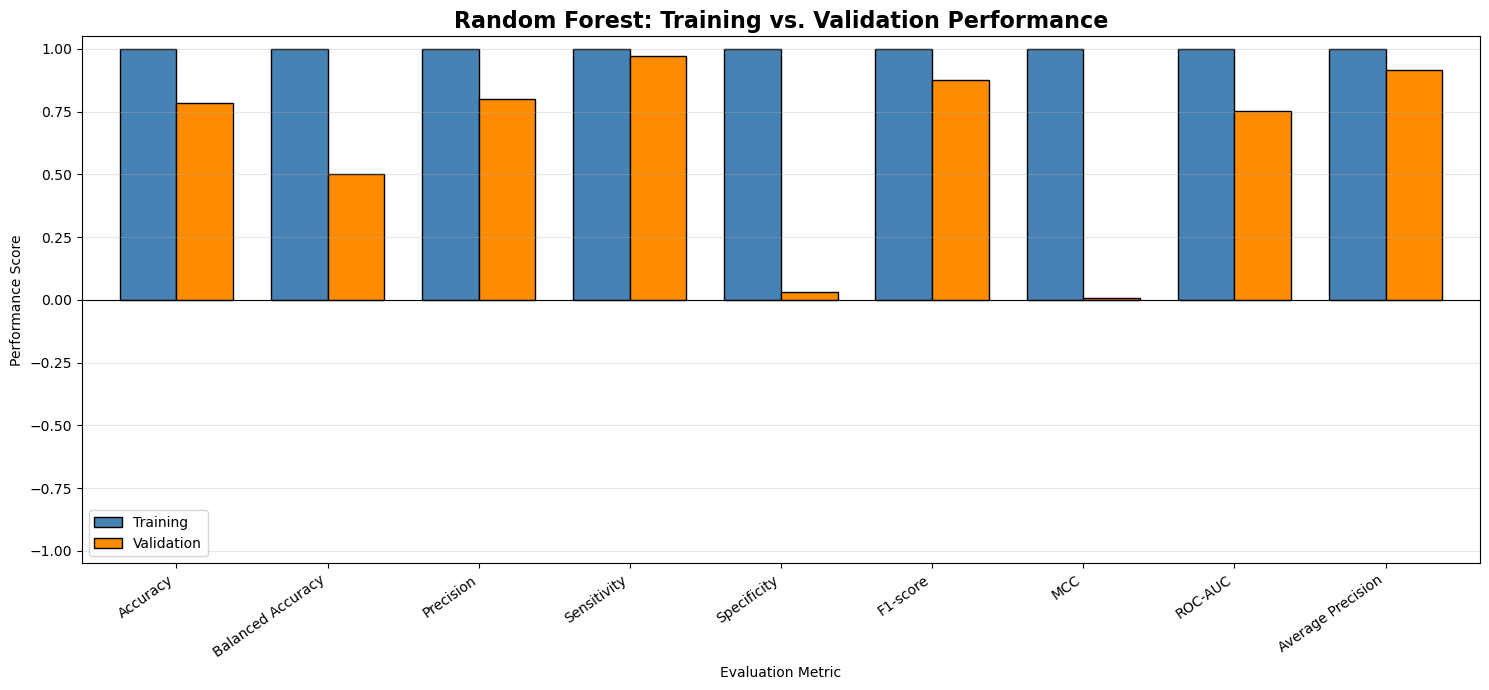

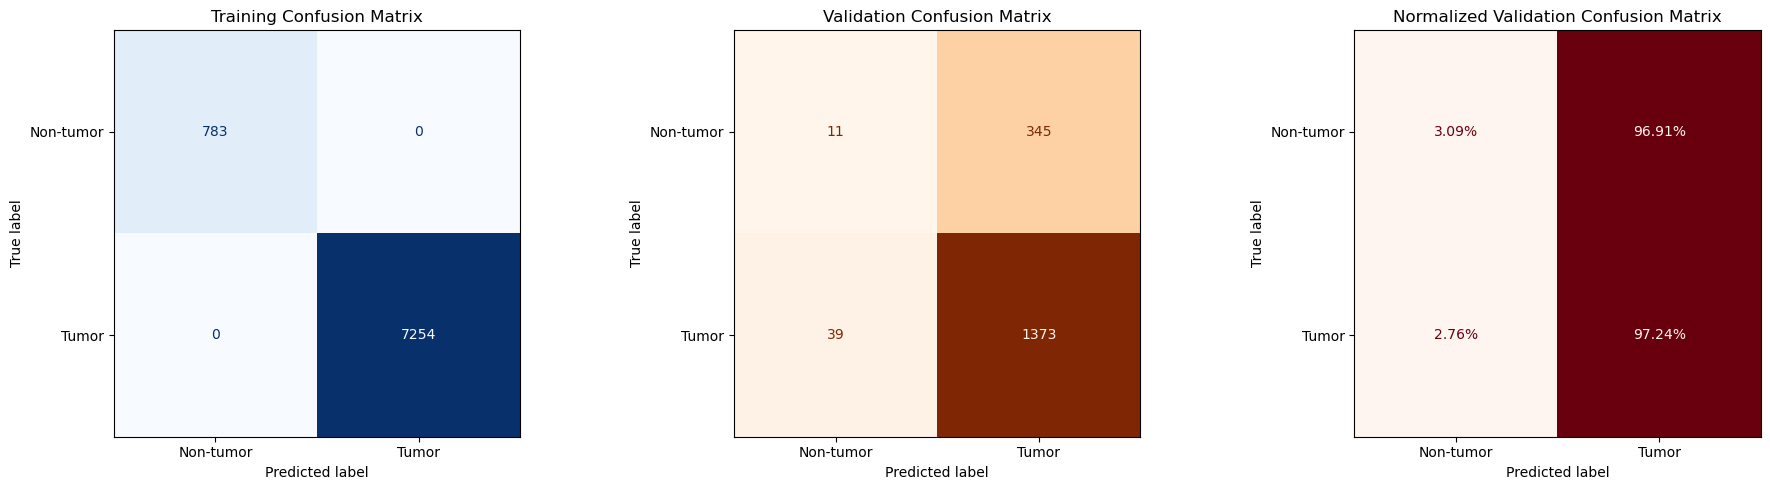

Classification performance visualizations completed.


In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Select performance metrics for visualization
selected_metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1-score",
    "MCC",
    "ROC-AUC",
    "Average Precision"
]

# Training versus validation performance
fig, ax = plt.subplots(figsize=(15, 7))

performance_summary.loc[
    selected_metrics,
    ["Training", "Validation"]
].plot(
    kind="bar",
    ax=ax,
    color=["steelblue", "darkorange"],
    edgecolor="black",
    width=0.75
)

ax.set_title(
    "Random Forest: Training vs. Validation Performance",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel("Performance Score")
ax.set_xlabel("Evaluation Metric")
ax.set_ylim(-1.05, 1.05)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# Generate confusion matrix visualizations
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

class_names = ["Non-tumor", "Tumor"]

# Training confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    labels=[0, 1],
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title("Training Confusion Matrix")

# Validation confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    labels=[0, 1],
    display_labels=class_names,
    cmap="Oranges",
    values_format="d",
    colorbar=False,
    ax=axes[1]
)

axes[1].set_title("Validation Confusion Matrix")

# Normalized validation confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    labels=[0, 1],
    display_labels=class_names,
    normalize="true",
    cmap="Reds",
    values_format=".2%",
    colorbar=False,
    ax=axes[2]
)

axes[2].set_title(
    "Normalized Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

print("Classification performance visualizations completed.")


## Cell 9B: ROC and Precision-Recall Curve Analysis

### Purpose

Evaluate the discriminatory capabilities of the Random
Forest classifier across multiple classification thresholds.

### Description

This cell generates:

- Receiver Operating Characteristic (ROC) curves.
- Precision-Recall (PR) curves.
- Training and validation ROC-AUC scores.
- Training and validation Average Precision scores.
- Reference curves for comparison.

### Why It Matters

Threshold-independent performance metrics provide insight
into the underlying discriminatory capabilities of a
classification model.

Precision-Recall analysis is particularly useful when
evaluating imbalanced medical imaging datasets.


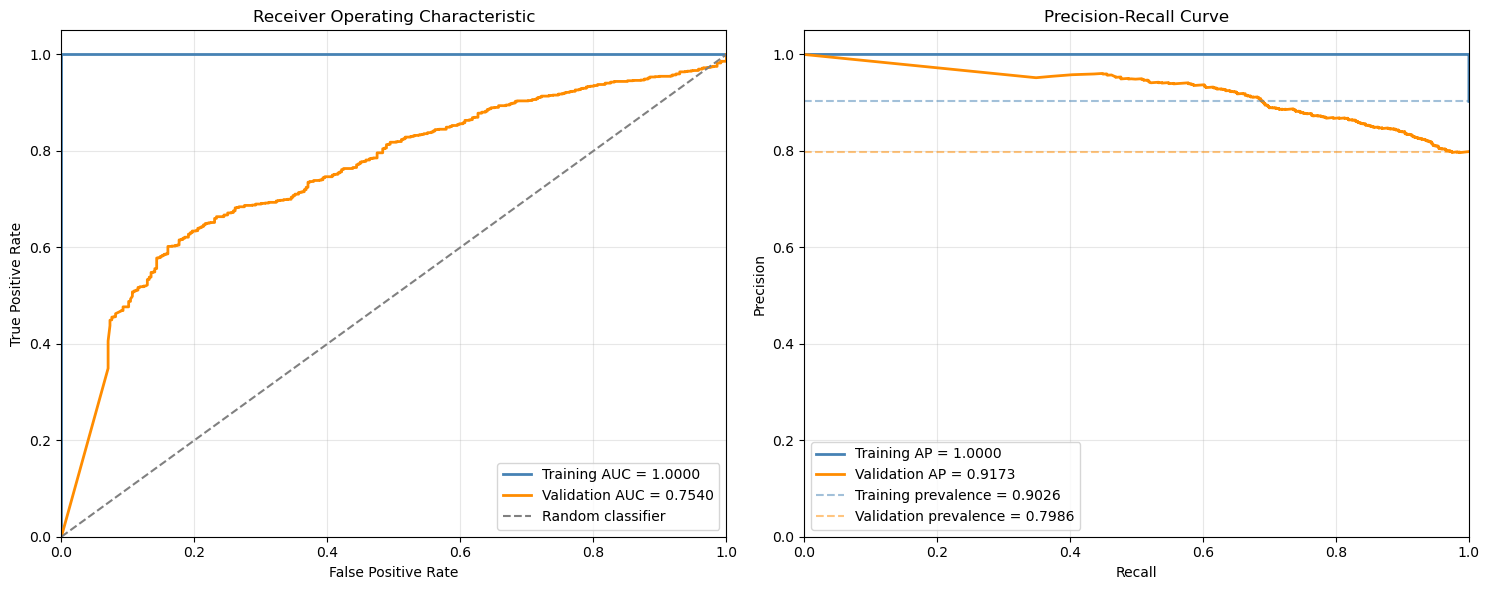

ROC and Precision-Recall analysis
--------------------------------------------------
Training ROC-AUC: 1.0000
Validation ROC-AUC: 0.7540
Training Average Precision: 1.0000
Validation Average Precision: 0.9173
Validation AP reference: 0.7986
Validation AP improvement: 0.1186

ROC and Precision-Recall analysis completed.


In [36]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Calculate ROC curve coordinates
train_fpr, train_tpr, train_roc_thresholds = roc_curve(
    y_train,
    y_train_prob
)

val_fpr, val_tpr, val_roc_thresholds = roc_curve(
    y_val,
    y_val_prob
)

# Calculate ROC-AUC scores
train_auc = roc_auc_score(y_train, y_train_prob)
val_auc = roc_auc_score(y_val, y_val_prob)

# Calculate Precision-Recall curves
train_precision, train_recall, _ = precision_recall_curve(
    y_train,
    y_train_prob
)

val_precision, val_recall, _ = precision_recall_curve(
    y_val,
    y_val_prob
)

# Calculate Average Precision
train_ap = average_precision_score(
    y_train,
    y_train_prob
)

val_ap = average_precision_score(
    y_val,
    y_val_prob
)

# Calculate positive-class prevalence
train_prevalence = np.mean(y_train)
val_prevalence = np.mean(y_val)

# Generate visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC curves
axes[0].plot(
    train_fpr,
    train_tpr,
    color="steelblue",
    linewidth=2,
    label=f"Training AUC = {train_auc:.4f}"
)

axes[0].plot(
    val_fpr,
    val_tpr,
    color="darkorange",
    linewidth=2,
    label=f"Validation AUC = {val_auc:.4f}"
)

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

axes[0].set_title("Receiver Operating Characteristic")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.05)
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# Precision-Recall curves
axes[1].plot(
    train_recall,
    train_precision,
    color="steelblue",
    linewidth=2,
    label=f"Training AP = {train_ap:.4f}"
)

axes[1].plot(
    val_recall,
    val_precision,
    color="darkorange",
    linewidth=2,
    label=f"Validation AP = {val_ap:.4f}"
)

axes[1].axhline(
    train_prevalence,
    linestyle="--",
    color="steelblue",
    alpha=0.5,
    label=f"Training prevalence = {train_prevalence:.4f}"
)

axes[1].axhline(
    val_prevalence,
    linestyle="--",
    color="darkorange",
    alpha=0.5,
    label=f"Validation prevalence = {val_prevalence:.4f}"
)

axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.05)
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("ROC and Precision-Recall analysis")
print("-" * 50)

print(f"Training ROC-AUC: {train_auc:.4f}")
print(f"Validation ROC-AUC: {val_auc:.4f}")

print(f"Training Average Precision: {train_ap:.4f}")
print(f"Validation Average Precision: {val_ap:.4f}")

print(f"Validation AP reference: {val_prevalence:.4f}")
print(f"Validation AP improvement: {val_ap - val_prevalence:.4f}")

print("\nROC and Precision-Recall analysis completed.")



## Cell 9C: Feature Importance and Decision Tree Analysis

### Purpose

Investigate the internal structure of the trained Random
Forest classifier and identify influential input features.

### Description

This cell analyzes:

- Impurity-based feature importance scores.
- The 20 highest-ranked pixel features.
- Spatial feature importance heatmaps.
- Decision tree depth distributions.
- Decision tree leaf distributions.

### Why It Matters

Feature importance analysis provides insight into the
input variables utilized by the Random Forest classifier.

Reshaping pixel feature importance scores into a
64 x 64 spatial representation allows exploratory
visualization of influential image locations.

### Research Limitation

Impurity-based feature importance does not establish
causality, clinical relevance, or tumor localization.

The spatial importance heatmap is not a tumor segmentation
mask and must not be interpreted as one.


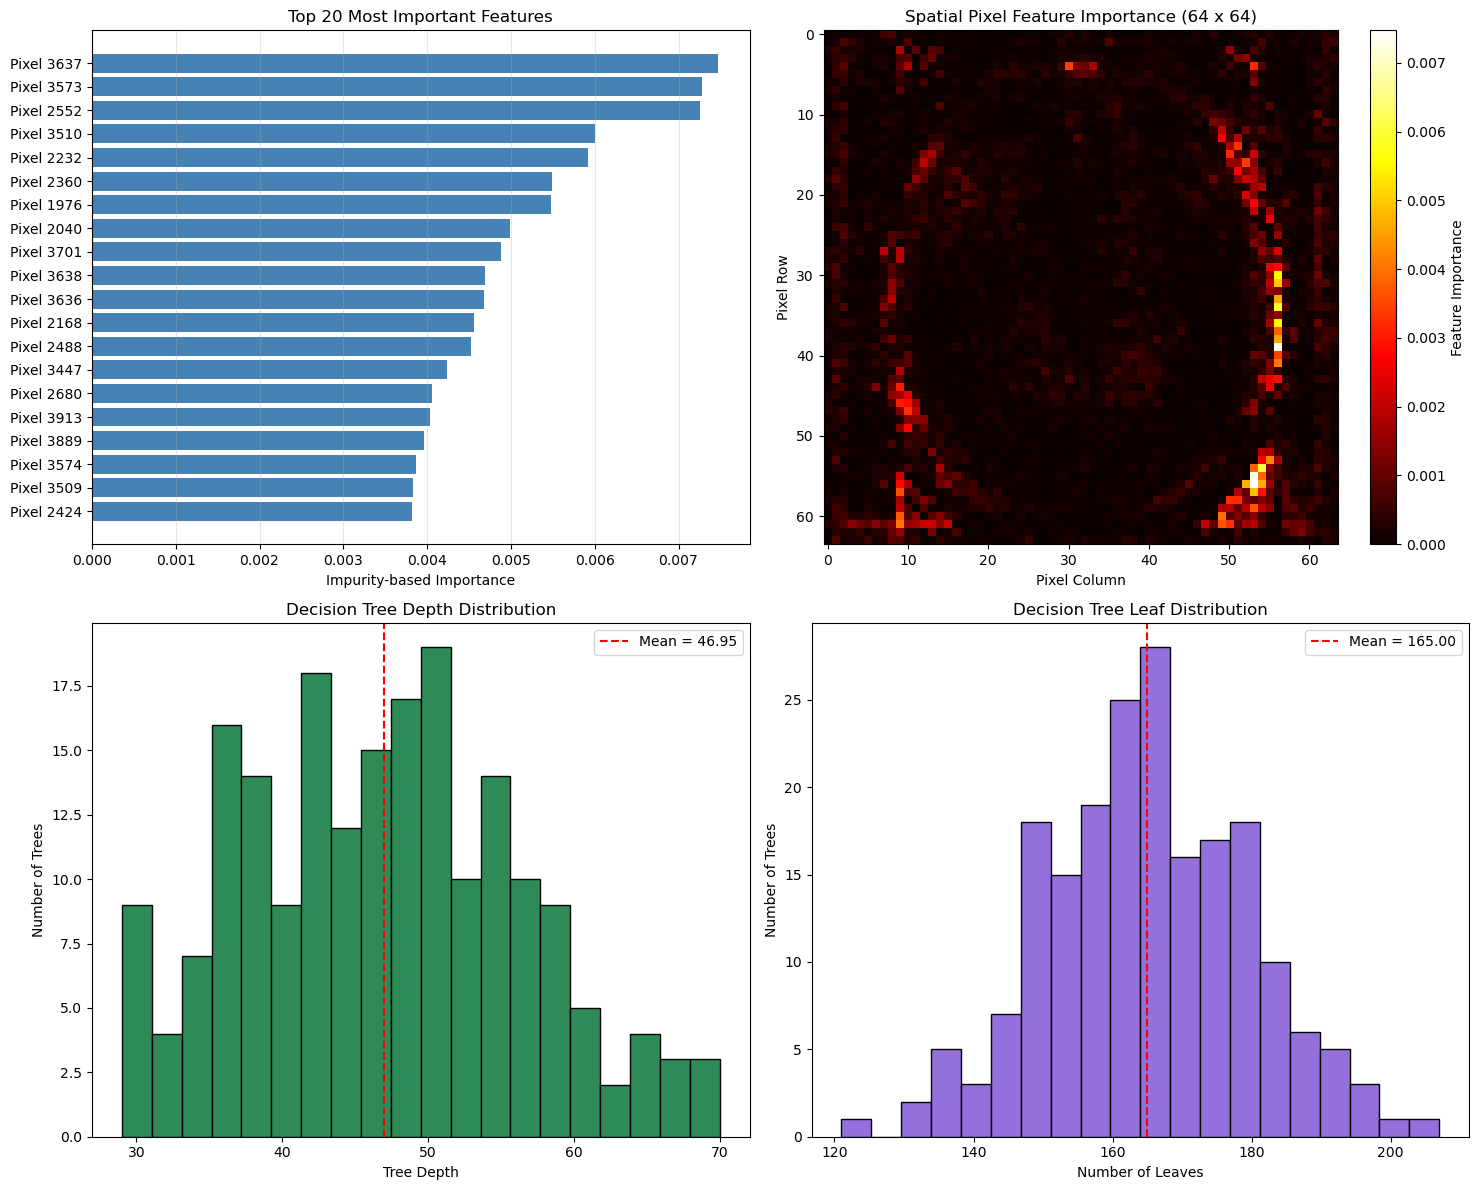

Top 20 Random Forest features
------------------------------------------------------------


,Feature Index,Pixel Row,Pixel Column,Importance
0,3637,56,53,0.007474
1,3573,55,53,0.007282
2,2552,39,56,0.007256
3,3510,54,54,0.006006
4,2232,34,56,0.005917
5,2360,36,56,0.005492
6,1976,30,56,0.005481
7,2040,31,56,0.004986
8,3701,57,53,0.004886
9,3638,56,54,0.004691



Decision tree statistics
--------------------------------------------------
Minimum tree depth: 29
Maximum tree depth: 70
Average tree depth: 46.95

Minimum leaves: 121
Maximum leaves: 207
Average leaves: 165.0

Total feature importance: 1.0

Feature importance analysis completed.


In [37]:

# Extract impurity-based feature importance scores
feature_importances = rf_model.feature_importances_

# Validate feature importance dimensions
assert len(feature_importances) == NUM_FEATURES
assert np.isfinite(feature_importances).all()

# Reshape feature importance into spatial dimensions
importance_heatmap = feature_importances.reshape(
    RF_IMAGE_SIZE
)

# Identify the 20 most important features
TOP_N = 20

top_indices = np.argsort(
    feature_importances
)[-TOP_N:][::-1]

top_importances = feature_importances[top_indices]

# Extract decision tree statistics
tree_depths = np.asarray([
    tree.get_depth()
    for tree in rf_model.estimators_
])

tree_leaves = np.asarray([
    tree.get_n_leaves()
    for tree in rf_model.estimators_
])

# Generate visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Top feature importance bar chart
axes[0, 0].barh(
    np.arange(TOP_N),
    top_importances,
    color="steelblue"
)

axes[0, 0].set_yticks(np.arange(TOP_N))

axes[0, 0].set_yticklabels([
    f"Pixel {index}"
    for index in top_indices
])

axes[0, 0].invert_yaxis()
axes[0, 0].set_xlabel("Impurity-based Importance")
axes[0, 0].set_title("Top 20 Most Important Features")
axes[0, 0].grid(axis="x", alpha=0.3)

# Spatial feature importance heatmap
heatmap = axes[0, 1].imshow(
    importance_heatmap,
    cmap="hot",
    interpolation="nearest"
)

axes[0, 1].set_title(
    "Spatial Pixel Feature Importance (64 x 64)"
)

axes[0, 1].set_xlabel("Pixel Column")
axes[0, 1].set_ylabel("Pixel Row")

fig.colorbar(
    heatmap,
    ax=axes[0, 1],
    label="Feature Importance"
)

# Decision tree depth distribution
axes[1, 0].hist(
    tree_depths,
    bins=20,
    color="seagreen",
    edgecolor="black"
)

axes[1, 0].axvline(
    tree_depths.mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {tree_depths.mean():.2f}"
)

axes[1, 0].set_title("Decision Tree Depth Distribution")
axes[1, 0].set_xlabel("Tree Depth")
axes[1, 0].set_ylabel("Number of Trees")
axes[1, 0].legend()

# Decision tree leaf distribution
axes[1, 1].hist(
    tree_leaves,
    bins=20,
    color="mediumpurple",
    edgecolor="black"
)

axes[1, 1].axvline(
    tree_leaves.mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {tree_leaves.mean():.2f}"
)

axes[1, 1].set_title("Decision Tree Leaf Distribution")
axes[1, 1].set_xlabel("Number of Leaves")
axes[1, 1].set_ylabel("Number of Trees")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Display top feature importance table
feature_importance_table = pd.DataFrame({
    "Feature Index": top_indices,

    "Pixel Row": (
        top_indices // RF_IMAGE_SIZE[1]
    ),

    "Pixel Column": (
        top_indices % RF_IMAGE_SIZE[1]
    ),

    "Importance": top_importances
})

print("Top 20 Random Forest features")
print("-" * 60)

display(feature_importance_table)

print("\nDecision tree statistics")
print("-" * 50)

print("Minimum tree depth:", tree_depths.min())
print("Maximum tree depth:", tree_depths.max())
print("Average tree depth:", tree_depths.mean())

print("\nMinimum leaves:", tree_leaves.min())
print("Maximum leaves:", tree_leaves.max())
print("Average leaves:", tree_leaves.mean())

print("\nTotal feature importance:",
      feature_importances.sum())

print("\nFeature importance analysis completed.")


## Cell 9D: Classification Threshold Optimization

### Purpose

Investigate alternative binary classification thresholds
for the trained Random Forest classifier.

### Description

The classification threshold is evaluated across a range
of candidate values using validation data exclusively.

For each threshold, the following metrics are calculated:

- Accuracy
- Balanced Accuracy
- Sensitivity
- Specificity
- Precision
- F1-score
- Matthews Correlation Coefficient

The threshold maximizing validation balanced accuracy
is selected for exploratory analysis.

### Why It Matters

The default classification threshold may not provide an
appropriate balance between sensitivity and specificity
when evaluating imbalanced datasets.

Threshold optimization may improve classification
decisions without modifying the trained Random Forest.

### Experimental Limitation

Threshold selection and evaluation use the same validation
dataset. Consequently, the optimized validation performance
is a model-selection result, not an independent estimate
of generalization.

The held-out testing dataset remains untouched.


Classification threshold optimization
------------------------------------------------------------
Default threshold: 0.5
Selected threshold: 0.95


,Default Threshold (0.50),Optimized Threshold,Difference
Accuracy,0.7828,0.6731,-0.1097
Balanced Accuracy,0.5016,0.7155,0.2139
Precision,0.7992,0.9229,0.1237
Sensitivity,0.9724,0.6445,-0.3279
Specificity,0.0309,0.7865,0.7556
F1-score,0.8773,0.7590,-0.1184
MCC,0.0079,0.3480,0.3401


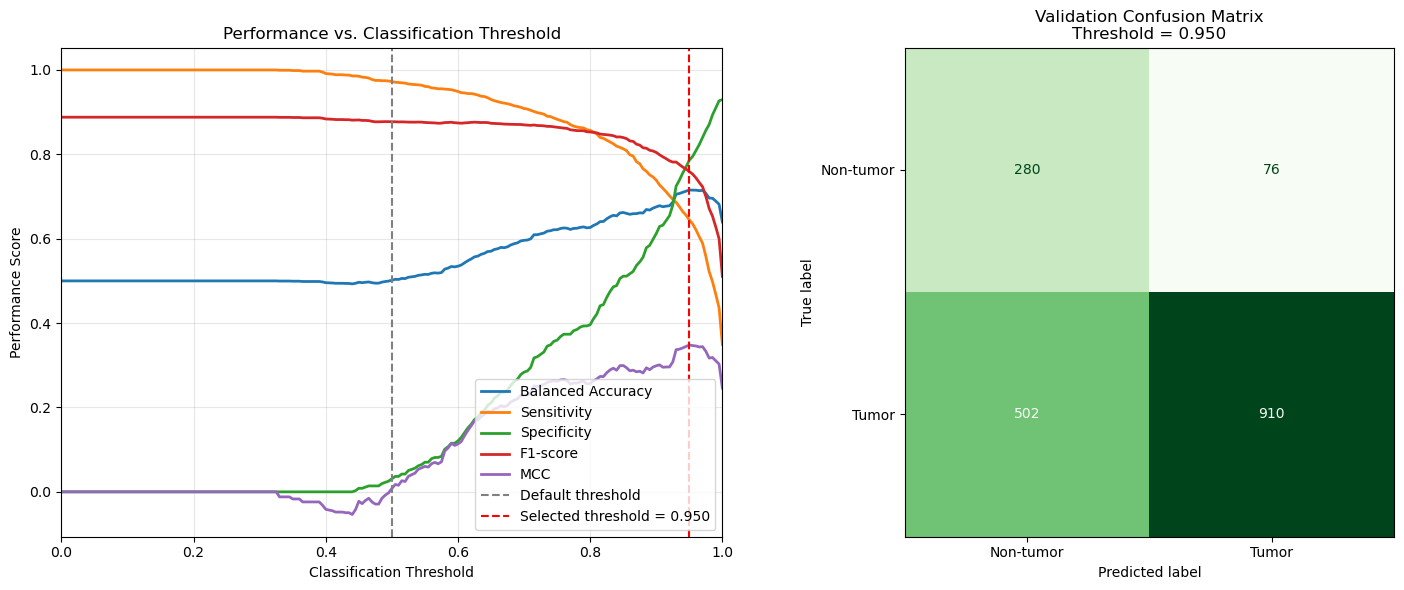


Optimized validation confusion matrix:
[[280  76]
 [502 910]]

Threshold optimization completed successfully.
Held-out testing dataset remains untouched.


In [38]:

# Define candidate classification thresholds
thresholds = np.linspace(0.0, 1.0, 201)

threshold_results = []

# Evaluate candidate thresholds
for threshold in thresholds:

    threshold_predictions = (
        y_val_prob >= threshold
    ).astype(np.int32)

    tn_t, fp_t, fn_t, tp_t = confusion_matrix(
        y_val,
        threshold_predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity_t = tp_t / (tp_t + fn_t)
    specificity_t = tn_t / (tn_t + fp_t)

    threshold_results.append({

        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_val,
            threshold_predictions
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_val,
            threshold_predictions
        ),

        "Sensitivity": sensitivity_t,

        "Specificity": specificity_t,

        "Precision": precision_score(
            y_val,
            threshold_predictions,
            zero_division=0
        ),

        "F1-score": f1_score(
            y_val,
            threshold_predictions,
            zero_division=0
        ),

        "MCC": matthews_corrcoef(
            y_val,
            threshold_predictions
        )
    })

# Construct threshold evaluation table
threshold_df = pd.DataFrame(threshold_results)

# Select threshold maximizing balanced accuracy
best_index = threshold_df[
    "Balanced Accuracy"
].idxmax()

best_threshold = float(
    threshold_df.loc[best_index, "Threshold"]
)

best_threshold_metrics = threshold_df.loc[best_index]

# Generate optimized validation predictions
y_val_pred_optimized = (
    y_val_prob >= best_threshold
).astype(np.int32)

# Construct optimized confusion matrix
optimized_cm = confusion_matrix(
    y_val,
    y_val_pred_optimized,
    labels=[0, 1]
)

# Compare default and optimized performance
comparison_metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1-score",
    "MCC"
]

threshold_comparison = pd.DataFrame({

    "Default Threshold (0.50)": [
        val_metrics[metric]
        for metric in comparison_metrics
    ],

    "Optimized Threshold": [
        best_threshold_metrics[metric]
        for metric in comparison_metrics
    ]

}, index=comparison_metrics)

threshold_comparison["Difference"] = (
    threshold_comparison["Optimized Threshold"] -
    threshold_comparison["Default Threshold (0.50)"]
)

# Display threshold optimization results
print("Classification threshold optimization")
print("-" * 60)

print("Default threshold:", 0.50)
print("Selected threshold:", round(best_threshold, 4))

display(threshold_comparison.round(4))

# Visualize threshold-dependent performance
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for metric in [
    "Balanced Accuracy",
    "Sensitivity",
    "Specificity",
    "F1-score",
    "MCC"
]:

    axes[0].plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        linewidth=2,
        label=metric
    )

axes[0].axvline(
    0.50,
    color="gray",
    linestyle="--",
    label="Default threshold"
)

axes[0].axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.3f}"
)

axes[0].set_title("Performance vs. Classification Threshold")
axes[0].set_xlabel("Classification Threshold")
axes[0].set_ylabel("Performance Score")
axes[0].set_xlim(0, 1)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Display optimized confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=optimized_cm,
    display_labels=["Non-tumor", "Tumor"]
).plot(
    ax=axes[1],
    cmap="Greens",
    values_format="d",
    colorbar=False
)

axes[1].set_title(
    f"Validation Confusion Matrix\n"
    f"Threshold = {best_threshold:.3f}"
)

plt.tight_layout()
plt.show()

print("\nOptimized validation confusion matrix:")
print(optimized_cm)

print("\nThreshold optimization completed successfully.")
print("Held-out testing dataset remains untouched.")



## Cell 10: Model Serialization and Experimental Results

### Purpose

Preserve the trained Random Forest classifier and its
associated experimental results for future analysis,
reproducibility, and comparative evaluation.

### Description

This cell saves:

- Trained Random Forest classifier.
- Model hyperparameter configuration.
- Feature extraction configuration.
- Training and validation performance metrics.
- Dataset partition statistics.
- Feature importance scores.
- Classification threshold optimization results.
- Validation predictions and probability scores.
- Experimental metadata.

### Why It Matters

Model serialization enables trained machine learning
models to be reloaded without repeating the training
process.

Preserving experimental results supports reproducibility,
comparative analysis, and future research documentation.

### Experimental Status

This model represents an exploratory raw-pixel Random
Forest baseline.

Patient-level independence, duplicate image checks,
and final held-out testing remain pending.


In [39]:
import joblib
import json
import hashlib
import platform
import sklearn

from datetime import datetime, timezone

# Define experiment information
EXPERIMENT_ID = "RF-01_Raw_Pixel_Baseline"

# Define model output directory
MODEL_DIR = (
    PROJECT_ROOT /
    "Code" /
    "models" /
    "Model_2_Random_Forest"
)

OUTPUT_DIR = (
    MODEL_DIR /
    "outputs" /
    EXPERIMENT_ID
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Calculate split manifest fingerprint
split_manifest_hash = hashlib.sha256(
    SPLIT_MANIFEST_PATH.read_bytes()
).hexdigest()

# Save trained model
MODEL_PATH = OUTPUT_DIR / "random_forest_model.joblib"

joblib.dump(
    rf_model,
    MODEL_PATH,
    compress=3
)

# Save training and validation performance metrics
performance_summary.to_csv(
    OUTPUT_DIR / "performance_metrics.csv"
)

# Save dataset partition summary
partition_summary.to_csv(
    OUTPUT_DIR / "dataset_partition_summary.csv",
    index=False
)

# Save threshold optimization results
threshold_df.to_csv(
    OUTPUT_DIR / "threshold_optimization.csv",
    index=False
)

# Save threshold comparison
threshold_comparison.to_csv(
    OUTPUT_DIR / "threshold_comparison.csv"
)

# Save complete feature importance scores
all_feature_importances = pd.DataFrame({
    "Feature Index": np.arange(NUM_FEATURES),

    "Pixel Row": (
        np.arange(NUM_FEATURES) // RF_IMAGE_SIZE[1]
    ),

    "Pixel Column": (
        np.arange(NUM_FEATURES) % RF_IMAGE_SIZE[1]
    ),

    "Importance": feature_importances
})

all_feature_importances.to_csv(
    OUTPUT_DIR / "feature_importances.csv",
    index=False
)

# Save spatial feature importance matrix
np.save(
    OUTPUT_DIR / "feature_importance_heatmap.npy",
    importance_heatmap
)

# Save validation predictions
validation_results = pd.DataFrame({

    "Image Path": [
        Path(path).resolve().relative_to(
            PROJECT_ROOT.resolve()
        ).as_posix()
        for path in paths_val
    ],

    "Actual Label": y_val,

    "Default Prediction": y_val_pred,

    "Tumor Probability Score": y_val_prob,

    "Optimized Prediction": y_val_pred_optimized
})

validation_results.to_csv(
    OUTPUT_DIR / "validation_predictions.csv",
    index=False
)

# Construct experimental metadata
experiment_metadata = {

    "experiment_id": EXPERIMENT_ID,

    "model_name": "Random Forest",

    "model_number": 2,

    "task": "Binary Brain Tumor Classification",

    "experiment_status": "Exploratory baseline",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "random_seed": int(SEED),

    "total_images": int(len(X)),

    "training_images": int(len(X_train)),

    "validation_images": int(len(X_val)),

    "testing_images": int(len(X_test)),

    "testing_evaluated": False,

    "preprocessing": {

        "initial_image_size": [224, 224],

        "feature_image_size": list(RF_IMAGE_SIZE),

        "feature_type": "Flattened pixel intensities",

        "number_of_features": int(NUM_FEATURES),

        "use_clahe": bool(USE_CLAHE),

        "normalization": "1st-99th percentile clipping",

        "intensity_range": [0.0, 1.0]
    },

    "partitioning": {

        "method": "Filename-based series grouping",

        "patient_independence_verified": False,

        "duplicate_content_audit_completed": False,

        "split_manifest_sha256": split_manifest_hash
    },

    "hyperparameters": rf_model.get_params(),

    "training_time_seconds": float(training_time),

    "feature_extraction_time_seconds": float(
        elapsed_time
    ),

    "average_tree_depth": float(tree_depths.mean()),

    "average_tree_leaves": float(tree_leaves.mean()),

    "default_threshold": 0.50,

    "optimized_threshold": float(best_threshold),

    "threshold_selection_dataset": "Validation",

    "threshold_selection_metric": "Balanced Accuracy",

    "training_metrics": {
        key: float(value)
        for key, value in train_metrics.items()
    },

    "validation_metrics": {
        key: float(value)
        for key, value in val_metrics.items()
    },

    "optimized_validation_metrics": {
        key: float(best_threshold_metrics[key])
        for key in comparison_metrics
    },

    "software_versions": {

        "python": platform.python_version(),

        "numpy": np.__version__,

        "pandas": pd.__version__,

        "scikit_learn": sklearn.__version__
    }
}

# Save experimental metadata
with open(
    OUTPUT_DIR / "experiment_metadata.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        experiment_metadata,
        file,
        indent=4
    )

# Verify model serialization
reloaded_model = joblib.load(MODEL_PATH)

original_predictions = rf_model.predict(
    X_val[:100]
)

reloaded_predictions = reloaded_model.predict(
    X_val[:100]
)

assert np.array_equal(
    original_predictions,
    reloaded_predictions
)

assert np.allclose(
    rf_model.predict_proba(X_val[:100]),
    reloaded_model.predict_proba(X_val[:100])
)

# Display saved experimental artifacts
print("Random Forest experimental artifacts")
print("-" * 60)

for file_path in sorted(OUTPUT_DIR.iterdir()):

    if file_path.is_file():

        file_size = file_path.stat().st_size / 1024

        print(
            f"{file_path.name:<40}"
            f"{file_size:>12.2f} KB"
        )

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nModel serialization verified successfully.")
print("Exploratory Random Forest baseline completed.")
print("Held-out testing dataset remains untouched.")


Random Forest experimental artifacts
------------------------------------------------------------
dataset_partition_summary.csv                   0.19 KB
experiment_metadata.json                        3.45 KB
feature_importance_heatmap.npy                 32.12 KB
feature_importances.csv                       134.69 KB
performance_metrics.csv                         0.65 KB
random_forest_model.joblib                   1573.38 KB
threshold_comparison.csv                        0.54 KB
threshold_optimization.csv                     23.73 KB
validation_predictions.csv                    300.50 KB

Output directory:
c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Code\models\Model_2_Random_Forest\outputs\RF-01_Raw_Pixel_Baseline

Model serialization verified successfully.
Exploratory Random Forest baseline completed.
Held-out testing dataset remains untouched.


## Block 12: Confusion Matrix

## Block 13: Feature Importance

## Block 14: Visualize Important MRI Regions

## Block 15: Save the Trained Model